In [2]:
import pandas as pd

df = pd.read_csv("data/data1.csv")

print(df.shape)
print(df.columns.tolist())
df.head()

(4966, 129)
['R1-PA1:VH', 'R1-PM1:V', 'R1-PA2:VH', 'R1-PM2:V', 'R1-PA3:VH', 'R1-PM3:V', 'R1-PA4:IH', 'R1-PM4:I', 'R1-PA5:IH', 'R1-PM5:I', 'R1-PA6:IH', 'R1-PM6:I', 'R1-PA7:VH', 'R1-PM7:V', 'R1-PA8:VH', 'R1-PM8:V', 'R1-PA9:VH', 'R1-PM9:V', 'R1-PA10:IH', 'R1-PM10:I', 'R1-PA11:IH', 'R1-PM11:I', 'R1-PA12:IH', 'R1-PM12:I', 'R1:F', 'R1:DF', 'R1-PA:Z', 'R1-PA:ZH', 'R1:S', 'R2-PA1:VH', 'R2-PM1:V', 'R2-PA2:VH', 'R2-PM2:V', 'R2-PA3:VH', 'R2-PM3:V', 'R2-PA4:IH', 'R2-PM4:I', 'R2-PA5:IH', 'R2-PM5:I', 'R2-PA6:IH', 'R2-PM6:I', 'R2-PA7:VH', 'R2-PM7:V', 'R2-PA8:VH', 'R2-PM8:V', 'R2-PA9:VH', 'R2-PM9:V', 'R2-PA10:IH', 'R2-PM10:I', 'R2-PA11:IH', 'R2-PM11:I', 'R2-PA12:IH', 'R2-PM12:I', 'R2:F', 'R2:DF', 'R2-PA:Z', 'R2-PA:ZH', 'R2:S', 'R3-PA1:VH', 'R3-PM1:V', 'R3-PA2:VH', 'R3-PM2:V', 'R3-PA3:VH', 'R3-PM3:V', 'R3-PA4:IH', 'R3-PM4:I', 'R3-PA5:IH', 'R3-PM5:I', 'R3-PA6:IH', 'R3-PM6:I', 'R3-PA7:VH', 'R3-PM7:V', 'R3-PA8:VH', 'R3-PM8:V', 'R3-PA9:VH', 'R3-PM9:V', 'R3-PA10:IH', 'R3-PM10:I', 'R3-PA11:IH', 'R3-PM11:I', 

,R1-PA1:VH,R1-PM1:V,R1-PA2:VH,R1-PM2:V,R1-PA3:VH,R1-PM3:V,R1-PA4:IH,R1-PM4:I,R1-PA5:IH,R1-PM5:I,...,control_panel_log4,relay1_log,relay2_log,relay3_log,relay4_log,snort_log1,snort_log2,snort_log3,snort_log4,marker
0,70.399324,127673.0908,-49.572308,127648.0176,-169.578319,127723.2374,65.689611,605.91099,-57.003571,626.78553,...,0,0,0,0,0,0,0,0,0,NoEvents
1,73.688102,130280.7109,-46.300719,130255.6377,-166.278082,130355.9307,71.831719,483.59351,-50.947407,500.98896,...,0,0,0,0,0,0,0,0,0,NoEvents
2,73.733939,130305.7842,-46.254883,130280.7109,-166.232245,130381.0040,71.808800,483.59351,-50.913030,500.98896,...,0,0,0,0,0,0,0,0,0,NoEvents
3,74.083443,130581.5902,-45.899649,130556.5169,-165.882741,130656.8100,72.152575,482.86107,-50.437475,499.15786,...,0,0,0,0,0,0,0,0,0,NoEvents
4,74.553268,131083.0556,-45.424094,131057.9823,-165.424375,131158.2754,72.118198,484.50906,-50.013486,497.69298,...,0,0,0,0,0,0,0,0,0,NoEvents


In [3]:
import os
print(os.getcwd())
print(os.listdir())

/Users/rohan/scada-project
['01_data_exploration.ipynb', 'class_distribution.png', '.ipynb_checkpoints', 'venv', 'data']


In [4]:
print(df["marker"].value_counts())

marker
Attack      3866
Natural      927
NoEvents     173
Name: count, dtype: int64


In [5]:
import pandas as pd
import glob

# find all 15 csv files automatically
all_files = sorted(glob.glob("data/data*.csv"))
print(f"Found {len(all_files)} files")

# load and combine them  into one big dataframe
df_all = pd.concat([pd.read_csv(f) for f in all_files], ignore_index=True)

print(df_all.shape)
print(df_all["marker"].value_counts())

Found 15 files
(78377, 129)
marker
Attack      55663
Natural     18309
NoEvents     4405
Name: count, dtype: int64


In [6]:
print(df_all.isnull().sum().sum())  #total missing values across everything

0


In [7]:
df_all.to_csv("data/combined_power_system.csv", index=False)

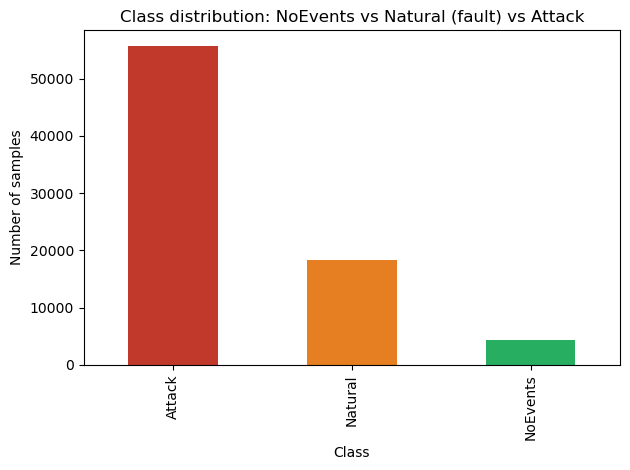

In [8]:
import matplotlib.pyplot as plt

df_all["marker"].value_counts().plot(kind="bar", color=["#c0392b", "#e67e22", "#27ae60"])
plt.title("Class distribution: NoEvents vs Natural (fault) vs Attack")
plt.ylabel("Number of samples")
plt.xlabel("Class")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

In [9]:
# How much does each column actually vary? Near-zero variance columns add little value.
print(df_all.describe().T[["mean", "std", "min", "max"]])

                     mean          std         min            max
R1-PA1:VH      -15.802424   100.876750 -179.988962     179.994691
R1-PM1:V    130764.039577  8546.118477    0.000000  151592.990400
R1-PA2:VH        2.175196   111.743169 -179.994691     179.994691
R1-PM2:V    131035.528095  5393.135370    0.000000  151567.917200
R1-PA3:VH        6.834315    97.065063 -179.994691     179.988962
...                   ...          ...         ...            ...
relay4_log       0.035597     0.185285    0.000000       1.000000
snort_log1       0.000051     0.007144    0.000000       1.000000
snort_log2       0.000051     0.007144    0.000000       1.000000
snort_log3       0.000089     0.009450    0.000000       1.000000
snort_log4       0.000077     0.008749    0.000000       1.000000

[128 rows x 4 columns]


In [10]:
log_cols = ["control_panel_log1", "control_panel_log2", "control_panel_log3", "control_panel_log4",
            "relay1_log", "relay2_log", "relay3_log", "relay4_log",
            "snort_log1", "snort_log2", "snort_log3", "snort_log4"]

print(df_all[log_cols].describe())

       control_panel_log1  control_panel_log2  control_panel_log3  \
count        78377.000000        78377.000000        78377.000000   
mean             0.000038            0.000038            0.000026   
std              0.006187            0.006187            0.005051   
min              0.000000            0.000000            0.000000   
25%              0.000000            0.000000            0.000000   
50%              0.000000            0.000000            0.000000   
75%              0.000000            0.000000            0.000000   
max              1.000000            1.000000            1.000000   

       control_panel_log4    relay1_log    relay2_log    relay3_log  \
count        78377.000000  78377.000000  78377.000000  78377.000000   
mean             0.000026      0.035916      0.026436      0.026500   
std              0.005051      0.186082      0.160430      0.160618   
min              0.000000      0.000000      0.000000      0.000000   
25%              0.0000

In [11]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# 1. Encode the target: Attack / Natural / NoEvents -> 0 / 1 / 2
le = LabelEncoder()
y = le.fit_transform(df_all["marker"])
print("Label mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

# 2. Features = everything except the label
X = df_all.drop(columns=["marker"])

# 3. Diagnose + fix infinite values (this is the actual bug fix)
inf_mask = np.isinf(X)
n_inf_rows = inf_mask.any(axis=1).sum()
cols_with_inf = inf_mask.any()
print(f"\nColumns with infinite values: {cols_with_inf[cols_with_inf].index.tolist()}")
print(f"Rows affected: {n_inf_rows} out of {len(X)} ({n_inf_rows/len(X)*100:.2f}%)")

# Replace inf/-inf with NaN so we can treat them uniformly with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# 4. Impute: fill any NaN (including the ones we just created) with each column's median
imputer = SimpleImputer(strategy="median")
X_clean = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# 5. Split, preserving class proportions given our known imbalance
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y, test_size=0.2, random_state=42, stratify=y
)

# 6. Train
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# 7. Evaluate
preds = rf.predict(X_test)
print("\n" + classification_report(y_test, preds, target_names=le.classes_))

# 8. Feature importances
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 15 most important features:")
print(importances.head(15))

Label mapping: {'Attack': np.int64(0), 'Natural': np.int64(1), 'NoEvents': np.int64(2)}

Columns with infinite values: ['R1-PA:Z', 'R2-PA:Z', 'R3-PA:Z', 'R4-PA:Z']
Rows affected: 6304 out of 78377 (8.04%)

              precision    recall  f1-score   support

      Attack       0.92      0.98      0.95     11133
     Natural       0.93      0.75      0.83      3662
    NoEvents       0.99      0.94      0.96       881

    accuracy                           0.93     15676
   macro avg       0.95      0.89      0.92     15676
weighted avg       0.93      0.93      0.92     15676


Top 15 most important features:
R4-PM2:V    0.023583
R1-PM2:V    0.020054
R2-PA:ZH    0.019192
R3-PM2:V    0.018196
R3-PA:ZH    0.018071
R4-PM7:V    0.016804
R4-PA:ZH    0.016282
R1-PA:ZH    0.015558
R2-PM1:V    0.014314
R1-PM5:I    0.014059
R2-PM5:I    0.014009
R4-PM3:V    0.014000
R3-PM5:I    0.013921
R4-PM5:I    0.013822
R4-PM1:V    0.013743
dtype: float64


In [12]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(y_test, preds)
cm_df = pd.DataFrame(cm, index=le.classes_, columns=le.classes_)
print("Rows = actual, Columns = predicted\n")
print(cm_df)

Rows = actual, Columns = predicted

          Attack  Natural  NoEvents
Attack     10936      190         7
Natural      902     2758         2
NoEvents      48        4       829


In [13]:
rf_bal = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight="balanced")
rf_bal.fit(X_train, y_train)
preds_bal = rf_bal.predict(X_test)

print(classification_report(y_test, preds_bal, target_names=le.classes_))
print(pd.DataFrame(confusion_matrix(y_test, preds_bal), index=le.classes_, columns=le.classes_))

              precision    recall  f1-score   support

      Attack       0.91      0.98      0.95     11133
     Natural       0.93      0.73      0.82      3662
    NoEvents       0.99      0.93      0.96       881

    accuracy                           0.92     15676
   macro avg       0.95      0.88      0.91     15676
weighted avg       0.92      0.92      0.92     15676

          Attack  Natural  NoEvents
Attack     10942      184         7
Natural      994     2666         2
NoEvents      57        4       820


In [14]:
import time
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score

nat = le.transform(["Natural"])[0]  # numeric label for the fault class

def summarize(name, p, secs):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Macro F1": f1_score(y_test, p, average="macro"),
        "Natural recall": recall_score(y_test, p, labels=[nat], average=None)[0],
        "Time (s)": secs,
    }

# Random Forest result from earlier (already computed as `preds`)
results = [summarize("Random Forest", preds, float("nan"))]

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
}

for name, model in models.items():
    t = time.time()
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    results.append(summarize(name, p, round(time.time() - t, 1)))
    print(f"done: {name}")

# SVM on a 20,000-row stratified subsample (full RBF SVM is too slow on 62k rows)
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=20000, stratify=y_train, random_state=42)
t = time.time()
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
svm.fit(X_sub, y_sub)
results.append(summarize("SVM (RBF, 20k subsample)", svm.predict(X_test), round(time.time() - t, 1)))
print("done: SVM")

comparison = pd.DataFrame(results).round(3).sort_values("Macro F1", ascending=False)
print(comparison.to_string(index=False))
comparison.to_csv("classifier_comparison.csv", index=False)

done: Logistic Regression
done: Decision Tree
done: KNN (k=5)
done: SVM
                   Model  Accuracy  Macro F1  Natural recall  Time (s)
           Random Forest     0.926     0.916           0.753       NaN
           Decision Tree     0.856     0.828           0.717       6.6
               KNN (k=5)     0.852     0.812           0.654       1.4
     Logistic Regression     0.716     0.423           0.073      10.3
SVM (RBF, 20k subsample)     0.717     0.329           0.077      25.7
